In [86]:
from scipy.special import gammaln
from scipy.special import factorial
from math import log as mathlog # why not use np.log ?
import numpy as np
import matplotlib.pyplot as plt

In [98]:
N = 20 # Try larger values
N_minus_1_fac = factorial(N-1, exact=True)
print(N_minus_1_fac)          # (N-1)!
print(mathlog(N_minus_1_fac)) # ln((N-1)!)
print(gammaln(N))             # ln(Gamma(N))
print()

true = 0
false = 0
for n in range(1, 20):
    logfac = mathlog(factorial(n-1, exact=True)) 
    gammaLn = gammaln(n)
    if logfac == gammaLn:
        true += 1
    else:
        print(f"n={n}")
        print(logfac)
        print(gammaLn)
        print()
        false += 1

print(f"True: {true}")
print(f"False: {false}")
print("This is some float comparison stuff")

121645100408832000
39.339884187199495
39.339884187199495

n=14
22.552163853123425
22.55216385312342

n=15
25.19122118273868
25.191221182738683

n=16
27.89927138384089
27.899271383840894

n=17
30.671860106080672
30.671860106080675

True: 15
False: 4
This is some float comparison stuff


/tmp/ipykernel_24692/4224058288.py:7: RuntimeWarning: divide by zero encountered in log
  return ((N - 1) * np.log(E) \


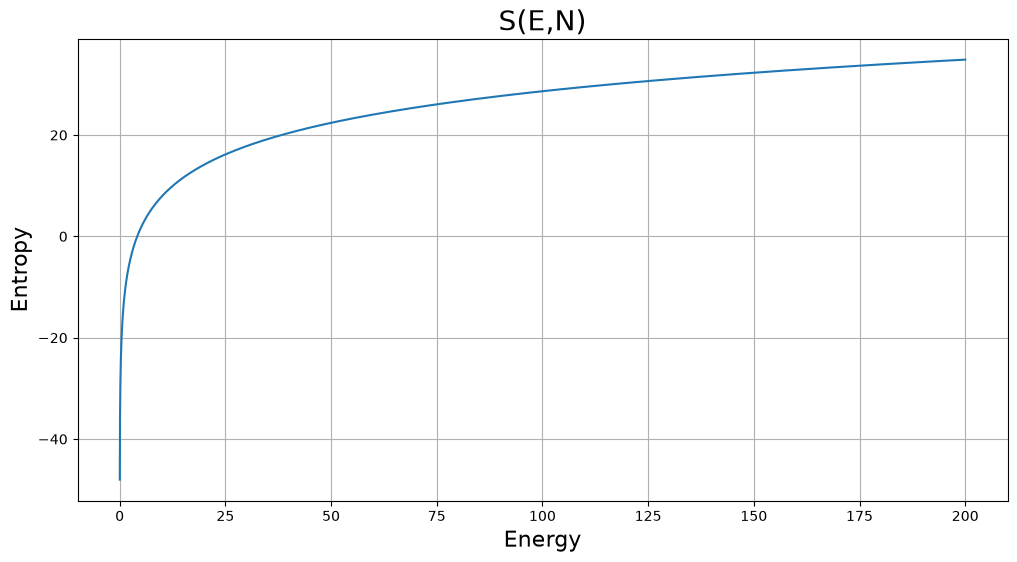

In [88]:
kB = 1
hbar_omega = 1
delta_E = 1
E = np.linspace(0,200,10000)

def log_Omega(N, E):
    return ((N - 1) * np.log(E) \
    - gammaln(N)                    # use log rules on Eq 1 from exercises
    - N * np.log( hbar_omega ) \
    + np.log(delta_E))

fig, ax = plt.subplots(figsize=(12,6))

S = log_Omega(10, E) * kB
ax.plot(E, S)
plt.xlabel('Energy', size=16)
plt.ylabel('Entropy', size=16)
plt.title('S(E,N)', size=20)
ax.grid()

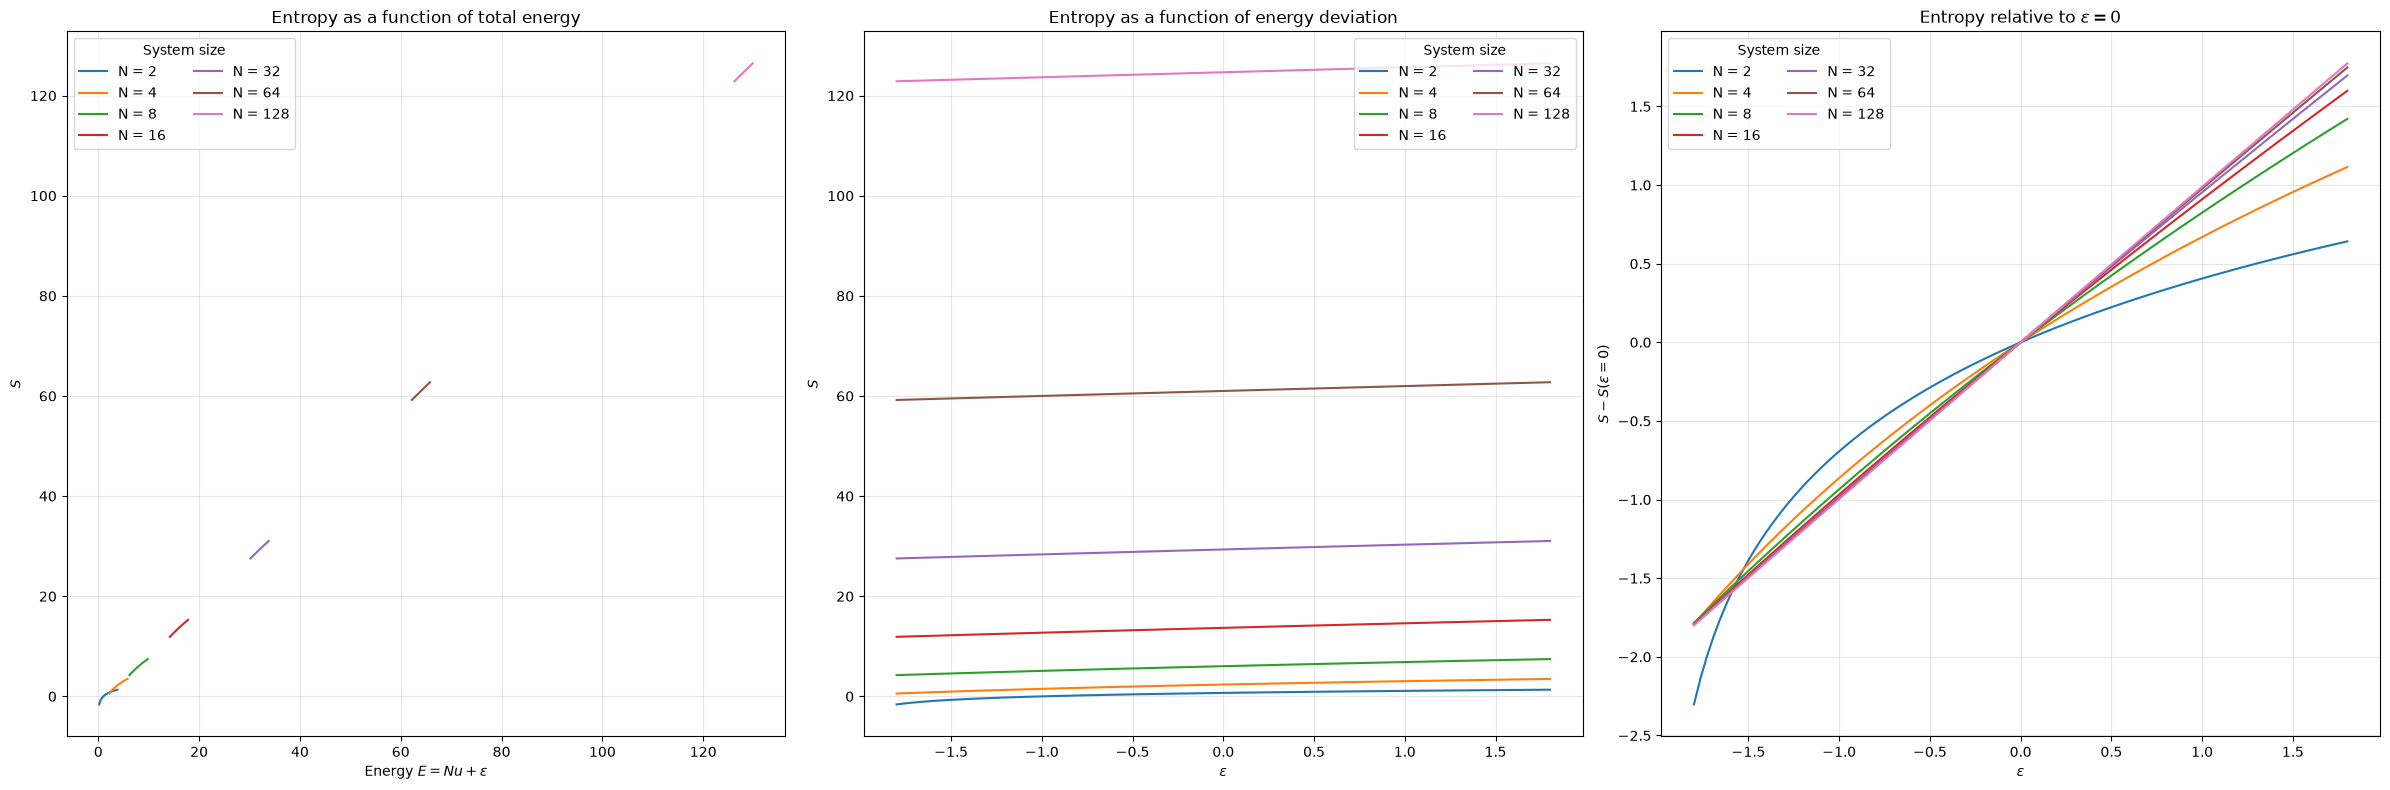

In [89]:
u = 1 
N = [2**n for n in range(1,8)]
epsilon = np.linspace(-1.8, 1.8, 100)

fig, axes = plt.subplots(1,3, figsize=(24,8))

for n in N:
    E = n*u + epsilon
    S = log_Omega(n, E) * kB
    S0 = log_Omega(n, n*u) * kB

    axes[0].plot(E, S, label=f"N = {n}")
    axes[1].plot(epsilon, S, label=f"N = {n}")
    axes[2].plot(epsilon, S - S0, label=f"N = {n}")

axes[0].set_title("Entropy as a function of total energy")
axes[0].set_xlabel("Energy $E = Nu + \\epsilon$")
axes[0].set_ylabel("$S$")

axes[1].set_title("Entropy as a function of energy deviation")
axes[1].set_xlabel("$\\epsilon$")
axes[1].set_ylabel("$S$")

axes[2].set_title("Entropy relative to $\\epsilon = 0$")
axes[2].set_xlabel("$\\epsilon$")
axes[2].set_ylabel("$S - S(\\epsilon=0)$")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(title="System size", ncol=2)

fig.tight_layout()
plt.show()

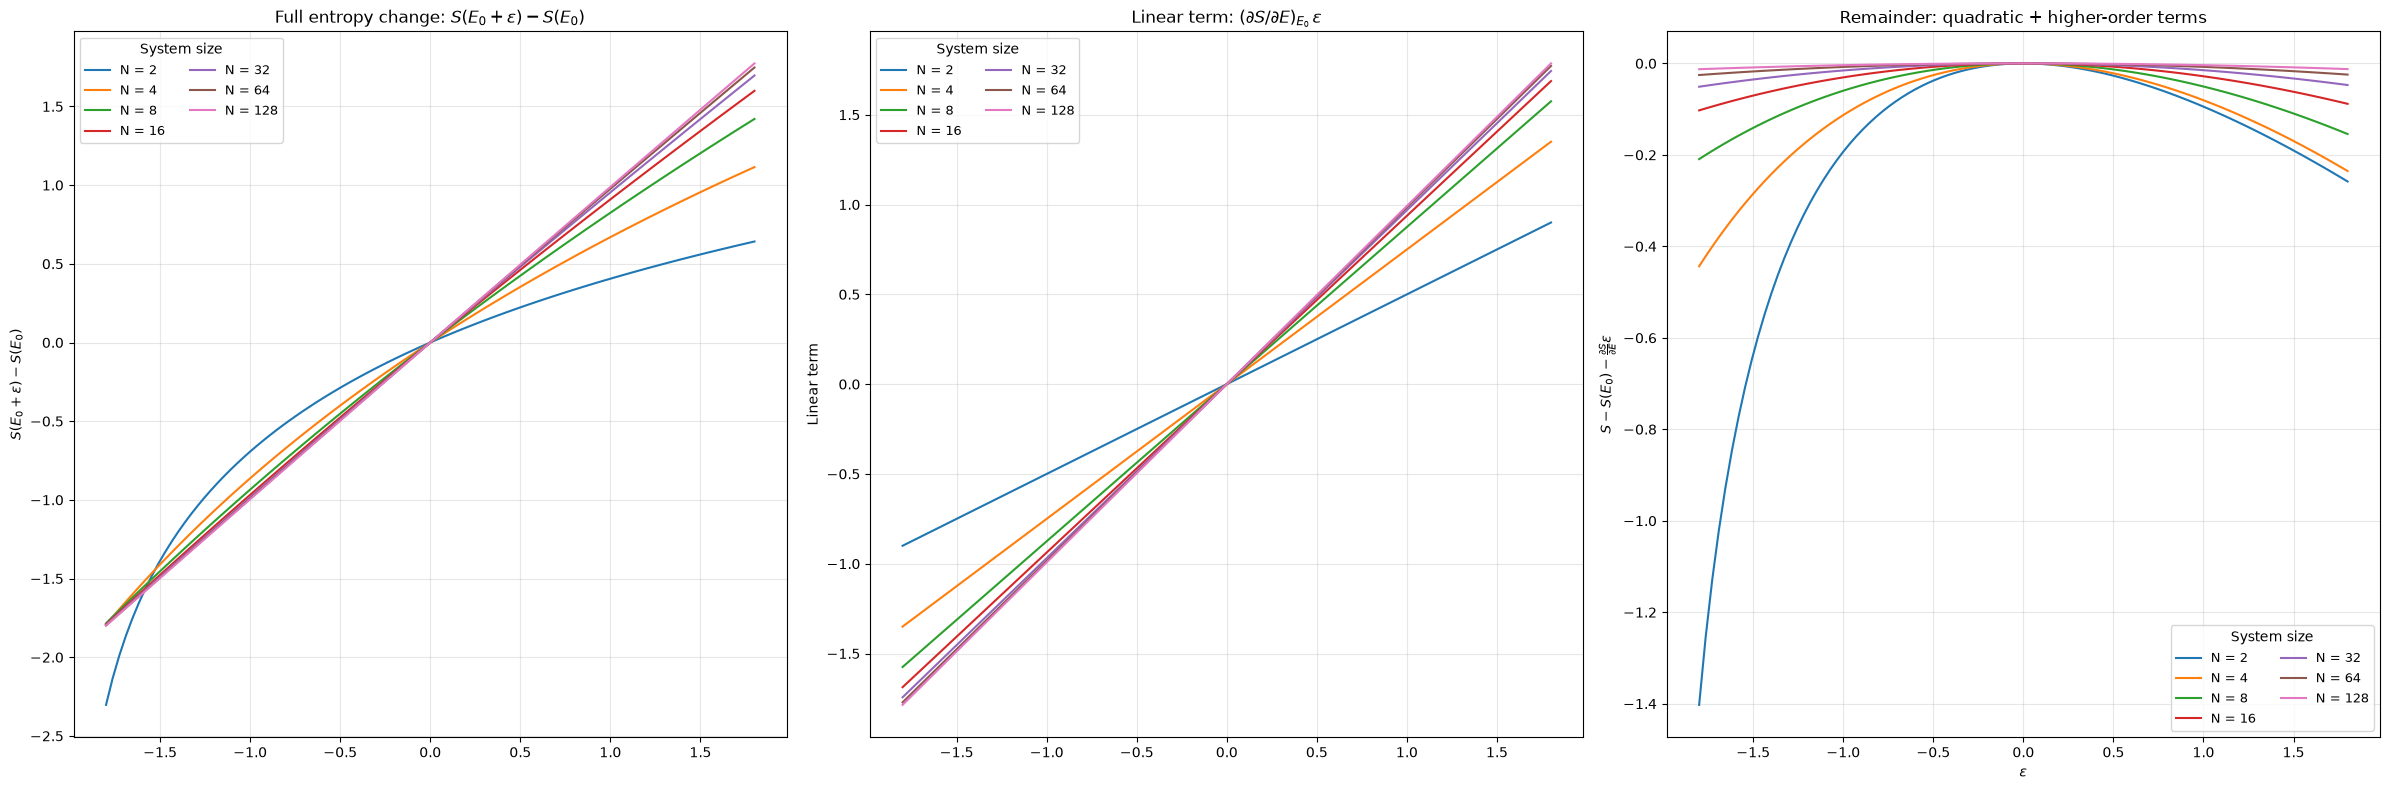

In [101]:
u = 1
N = [2**n for n in range(1, 8)]
epsilon = np.linspace(-1.8, 1.8, 100)

fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharex=True)

for n in N:
    E0 = n * u
    S = log_Omega(n, E0 + epsilon) * kB
    S0 = log_Omega(n, E0) * kB

    # slope at E0 via central difference
    h = 1e-4
    dSdE = (log_Omega(n, E0 + h) - log_Omega(n, E0 - h)) * kB / (2 * h)

    linear = dSdE * epsilon
    remainder = S - S0 - linear   # quadratic + higher-order terms

    axes[0].plot(epsilon, S - S0, label=f"N = {n}")
    axes[1].plot(epsilon, linear, label=f"N = {n}")
    axes[2].plot(epsilon, remainder, label=f"N = {n}")

axes[0].set_title(r"Full entropy change: $S(E_0+\epsilon) - S(E_0)$")
axes[0].set_ylabel(r"$S(E_0+\epsilon) - S(E_0)$")

axes[1].set_title(r"Linear term: $(\partial S/\partial E)_{E_0}\,\epsilon$")
axes[1].set_ylabel("Linear term")

axes[2].set_title(r"Remainder: quadratic + higher-order terms")
axes[2].set_ylabel(r"$S - S(E_0) - \frac{\partial S}{\partial E}\epsilon$")
axes[2].set_xlabel(r"$\epsilon$")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(title="System size", ncol=2, fontsize=9)

fig.tight_layout()
plt.show()

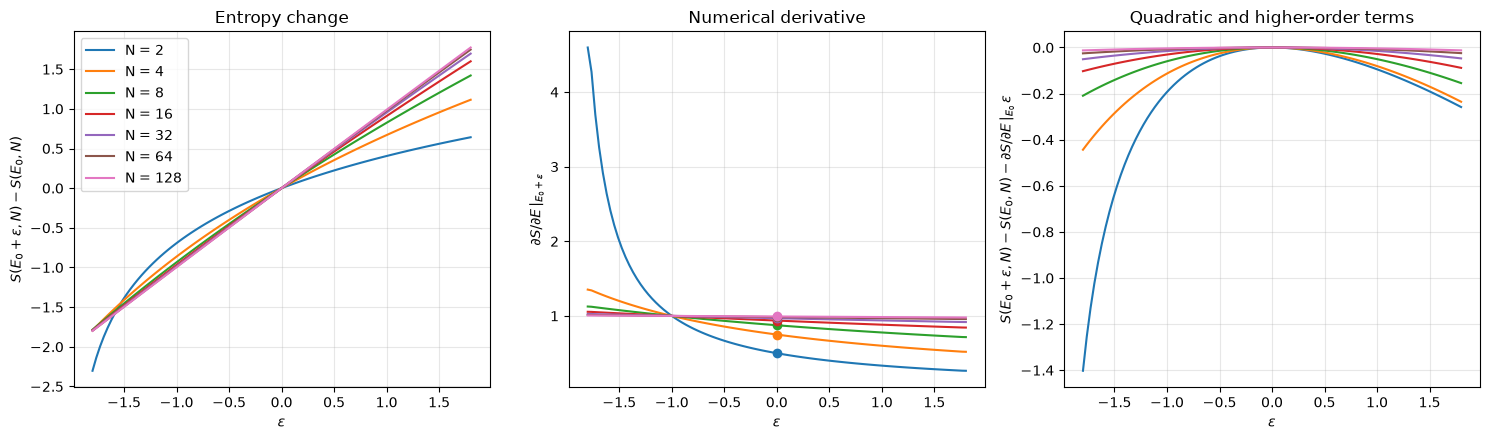

In [94]:
u = 1
N = [2**n for n in range(1,8)]
epsilon = np.linspace(-1.8, 1.8, 101)   
i0 = len(epsilon) // 2                  # index of epsilon = 0

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for n in N:
    E0 = n * u
    E = E0 + epsilon

    S = log_Omega(n, E) * kB
    S0 = S[i0]                          # S(E0, N)

    dSdE = np.gradient(S, E)            # numerical derivative at E0 + epsilon
    slope0 = dSdE[i0]                   # derivative at epsilon = 0

    remainder = S - S0 - slope0 * epsilon

    line, = axes[0].plot(epsilon, S - S0, label=f"N = {n}")
    color = line.get_color()
    axes[1].plot(epsilon, dSdE, color=color)
    axes[1].plot(epsilon[i0], slope0, "o", color=color)
    axes[2].plot(epsilon, remainder, color=color)

axes[0].set_ylabel(r"$S(E_0+\epsilon,N) - S(E_0,N)$")
axes[1].set_ylabel(r"$\partial S/\partial E\,|_{E_0+\epsilon}$")
axes[2].set_ylabel(r"$S(E_0+\epsilon,N) - S(E_0,N) - \partial S/\partial E\,|_{E_0}\,\epsilon$")

axes[0].set_title("Entropy change")
axes[1].set_title("Numerical derivative")
axes[2].set_title("Quadratic and higher-order terms")

for ax in axes:
    ax.set_xlabel(r"$\epsilon$")
    ax.grid(True, alpha=0.3)
axes[0].legend()

fig.tight_layout()
plt.show()

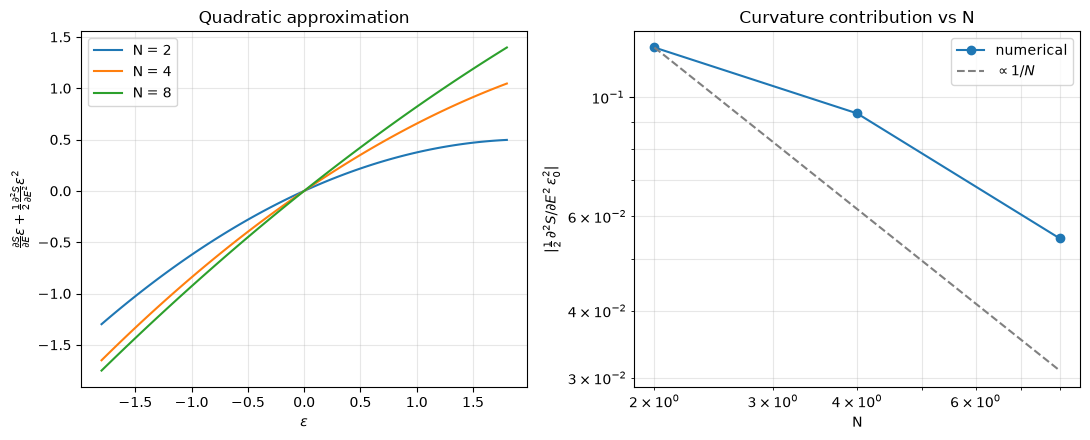

In [95]:
u = 1
eps0 = 1.0
h = eps0 / 100
N = [2, 4, 8]                        # as in the reference figure; try larger lists too
epsilon = np.linspace(-1.8, 1.8, 101)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

curv_contrib = []
for n in N:
    E0 = n * u
    S = lambda E: log_Omega(n, E) * kB

    S0 = S(E0)
    slope = (S(E0 + h) - S0) / h
    curv = (S(E0 + 2*h) - 2*S(E0 + h) + S0) / h**2

    # second-order Taylor approximation minus the constant term, over the epsilon interval
    approx = slope * epsilon + 0.5 * curv * epsilon**2
    axes[0].plot(epsilon, approx, label=f"N = {n}")

    # magnitude of the quadratic contribution at eps0
    curv_contrib.append(abs(0.5 * curv * eps0**2))

axes[0].set_xlabel(r"$\epsilon$")
axes[0].set_ylabel(r"$\frac{\partial S}{\partial E}\epsilon + \frac{1}{2}\frac{\partial^2 S}{\partial E^2}\epsilon^2$")
axes[0].set_title("Quadratic approximation")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

N_arr = np.array(N)
axes[1].loglog(N_arr, curv_contrib, "o-", label="numerical")
ref = curv_contrib[0] * N_arr[0] / N_arr          # 1/N line through the first point
axes[1].loglog(N_arr, ref, "--", color="gray", label=r"$\propto 1/N$")
axes[1].set_xlabel("N")
axes[1].set_ylabel(r"$|\frac{1}{2}\,\partial^2 S/\partial E^2\,\epsilon_0^2|$")
axes[1].set_title("Curvature contribution vs N")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend()

fig.tight_layout()
plt.show()